# Inteligencia Artificial con Aplicaciones en Economía I

- Profesora: Lina María Castro
- Universidad Externado de Colombia, Facultad de Economía
- Integrantes: Daniel Peña, Santiago González y Sebastián Mendoza

# Etapa 2. Construcción de variables, análisis exploratorio y K-Means

## Importar librerías

In [1]:
import os
import glob
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

## Mejorar visualización de los dataframes y los gráficos

In [2]:
pd.options.display.max_columns = None
pd.options.display.float_format = '{:,.2f}'.format
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

AZUL, ROJO, GRIS = "#2a6f97", "#d1495b", "#8d99ae"
COLORES = {"Sin coca": AZUL, "Con coca": ROJO}
SEMILLA = 42

## Establecer la ruta de los datasets

In [3]:
ARCHIVO_CLAVE = os.path.join('data', 'processed', 'panel_municipio_anio.csv')

def buscar_proyecto(raices, niveles=4):
    for raiz in raices:
        for n in range(niveles + 1):
            hallados = glob.glob(os.path.join(raiz, *(['*'] * n), ARCHIVO_CLAVE))
            if hallados:
                return hallados[0].replace(os.sep + ARCHIVO_CLAVE, '')
    return None

try:
    from google.colab import drive
    drive.mount('/content/drive')
    path = buscar_proyecto(['/content/drive/MyDrive', '/content'])
    if path is None:
        raise FileNotFoundError("Ejecute primero el notebook 01 o suba la carpeta del proyecto a Drive.")
    os.chdir(path)
except ImportError:
    if not os.path.exists(ARCHIVO_CLAVE) and os.path.exists(os.path.join('..', ARCHIVO_CLAVE)):
        os.chdir('..')
print("Carpeta de trabajo:", os.getcwd())

Carpeta de trabajo: /home/claude/out/proyecto_desercion_coca


## Cargar los datasets de la etapa 1

In [4]:
tipos = {'cod_mpio': str, 'cod_depto': str, 'cod_etc': str}
panel = pd.read_csv('data/processed/panel_municipio_anio.csv', dtype=tipos)
coca_ancho = pd.read_csv('data/processed/coca_2001_2024_ancho.csv', dtype=tipos)
print("Panel:", panel.shape, "| Coca 2001-2024:", coca_ancho.shape)

Panel: (15704, 67) | Coca 2001-2024: (319, 25)


## Construcción de variables (feature engineering)

### 1. Variable objetivo

In [5]:
ANIOS_OBJETIVO = [2022, 2023, 2024]
ANIOS_PREDICTORES = [2021, 2022, 2023]
ANIOS_REZAGO_MEN = [2019, 2020, 2021]

objetivo = (panel[panel['anio'].isin(ANIOS_OBJETIVO)]
            .groupby('cod_mpio')
            .agg(desercion_prom=('desercion', 'mean'), anios_con_dato=('desercion', 'count'),
                 des_primaria=('desercion_primaria', 'mean'), des_secundaria=('desercion_secundaria', 'mean'),
                 des_media=('desercion_media', 'mean'))
            .reset_index())
print("Municipios con deserción 2022-2024:", len(objetivo))
print("Años con dato por municipio:", objetivo['anios_con_dato'].value_counts().to_dict())

Municipios con deserción 2022-2024: 1122
Años con dato por municipio: {3: 1121, 1: 1}


### 2. Predictores 2021-2023 (coca, víctimas, población)

In [6]:
predictores = (panel[panel['anio'].isin(ANIOS_PREDICTORES)]
               .groupby('cod_mpio')
               .agg(ha_coca_prom=('ha_coca', 'mean'), victimas_prom=('victimas', 'mean'),
                    pob_total=('pob_total', 'mean'), pct_rural=('pct_rural', 'mean'),
                    pob_5_16=('poblacion_5_16', 'mean'))
               .reset_index())

### 3. Variables educativas del MEN rezagadas (2019-2021): todas las columnas

In [7]:
columnas_men = ['desercion', 'desercion_transicion', 'desercion_primaria', 'desercion_secundaria', 'desercion_media',
                'aprobacion', 'aprobacion_transicion', 'aprobacion_primaria', 'aprobacion_secundaria', 'aprobacion_media',
                'reprobacion', 'reprobacion_transicion', 'reprobacion_primaria', 'reprobacion_secundaria', 'reprobacion_media',
                'repitencia', 'repitencia_transicion', 'repitencia_primaria', 'repitencia_secundaria', 'repitencia_media',
                'cob_neta', 'cob_neta_transicion', 'cob_neta_primaria', 'cob_neta_secundaria', 'cob_neta_media',
                'cob_bruta', 'cob_bruta_transicion', 'cob_bruta_primaria', 'cob_bruta_secundaria', 'cob_bruta_media',
                'tasa_matriculacion_5_16']

rezagos = panel[panel['anio'].isin(ANIOS_REZAGO_MEN)].groupby('cod_mpio')[columnas_men].mean()
rezagos.columns = [f'{c}_lag' for c in rezagos.columns]
rezagos = rezagos.reset_index()

estructurales = (panel[panel['anio'].between(2015, 2017)].sort_values('anio')
                 .groupby('cod_mpio')[['tamano_grupo', 'sedes_internet']].last()
                 .rename(columns={'tamano_grupo': 'tamano_grupo_2017', 'sedes_internet': 'sedes_internet_2017'})
                 .reset_index())
print("Faltantes de 2017 completados con 2015-2016:",
      int(panel[panel['anio'] == 2017][['tamano_grupo', 'sedes_internet']].isnull().sum().sum()
          - estructurales[['tamano_grupo_2017', 'sedes_internet_2017']].isnull().sum().sum()))

Faltantes de 2017 completados con 2015-2016: 39


In [8]:
mismo_periodo = panel[panel['anio'].isin(ANIOS_OBJETIVO)].groupby('cod_mpio')[columnas_men].mean()
mismo_periodo.columns = [f'{c}_2224' for c in mismo_periodo.columns]
mismo_periodo = mismo_periodo.reset_index()

### 4. Integración de la base municipal

In [9]:
fijas = panel[panel['anio'] == 2024][['cod_mpio', 'municipio', 'cod_depto', 'departamento', 'cod_etc', 'etc', 'pdet', 'subregion_pdet']
                                    + ['ipm', 'ipm_cabecera', 'ipm_rural'] + [c for c in panel.columns if c.startswith('priv_')]]
fijas = pd.concat([fijas, panel[(panel['anio'] == 2019) & (panel['cod_mpio'] == '94663')][fijas.columns]])

base = fijas.copy()
for tabla in [objetivo, predictores, rezagos, estructurales, mismo_periodo, coca_ancho]:
    base = base.merge(tabla, on='cod_mpio', how='left')
print("Base integrada:", base.shape)

Base integrada: (1123, 124)


In [10]:
print("Sin deserción 2022-2024:", base.loc[base['desercion_prom'].isnull(), 'municipio'].tolist())
print("Sin IPM 2018:", base.loc[base['ipm'].isnull(), 'municipio'].tolist())
print("Sin rezagos del MEN:", base.loc[base['desercion_lag'].isnull(), 'municipio'].tolist())
base = base.dropna(subset=['desercion_prom', 'ipm', 'desercion_lag']).reset_index(drop=True)
print("Base municipal final:", base.shape)

Sin deserción 2022-2024: ['Mapiripana']
Sin IPM 2018: ['Nuevo Belén de Bajirá']
Sin rezagos del MEN: ['Nuevo Belén de Bajirá']


Base municipal final: (1121, 124)


In [11]:
columnas_ha = [c for c in base.columns if c.startswith('ha_') and c[3:].isdigit()]
print("Municipios fuera del SIMCI (coca = 0):", base[columnas_ha[0]].isnull().sum())
base[columnas_ha] = base[columnas_ha].fillna(0)

sin_cabecera = base['ipm_cabecera'].isnull()
print("Municipios sin IPM de cabecera:", sin_cabecera.sum(), "| % rural promedio:", round(base.loc[sin_cabecera, 'pct_rural'].mean(), 1))
base.loc[sin_cabecera, 'ipm_cabecera'] = base.loc[sin_cabecera, 'ipm']
print("Faltantes restantes en tamaño de grupo y sedes 2017:", base[['tamano_grupo_2017', 'sedes_internet_2017']].isnull().sum().to_dict())

Municipios fuera del SIMCI (coca = 0): 803
Municipios sin IPM de cabecera: 19 | % rural promedio: 99.4
Faltantes restantes en tamaño de grupo y sedes 2017: {'tamano_grupo_2017': 13, 'sedes_internet_2017': 2}


### 5. Variable objetivo: deserción alta

In [12]:
p75 = base['desercion_prom'].quantile(0.75)
base['desercion_alta'] = np.where(base['desercion_prom'] > p75, 1, 0)
base['desercion_alta_p80'] = np.where(base['desercion_prom'] > base['desercion_prom'].quantile(0.80), 1, 0)
base['desercion_alta_p90'] = np.where(base['desercion_prom'] > base['desercion_prom'].quantile(0.90), 1, 0)
print(f"Umbral P75: {p75:.2f} %")
print(base['desercion_alta'].value_counts(normalize=True))

Umbral P75: 4.76 %
desercion_alta
0   0.75
1   0.25
Name: proportion, dtype: float64


### 6. Variables de coca: presencia, intensidad, persistencia y dinámica 2001-2023

In [13]:
def columnas(desde, hasta):
    return [f'ha_{a}' for a in range(desde, hasta + 1)]

base['coca_presencia'] = np.where(base['ha_coca_prom'] > 0, 1, 0)
base['grupo_coca'] = np.where(base['coca_presencia'] == 1, 'Con coca', 'Sin coca')
base['log_ha_coca'] = np.log1p(base['ha_coca_prom'])
base['anios_coca'] = (base[columnas(2014, 2023)] > 0).sum(axis=1)
base['anios_coca_largo'] = (base[columnas(2001, 2023)] > 0).sum(axis=1)
base['log_ha_max_2001_2020'] = np.log1p(base[columnas(2001, 2020)].max(axis=1))
base['cambio_coca'] = np.log1p(base[columnas(2021, 2023)].mean(axis=1)) - np.log1p(base[columnas(2018, 2020)].mean(axis=1))

tuvo_antes = (base[columnas(2014, 2020)] > 0).any(axis=1)
tiene_ahora = base['coca_presencia'] == 1
base['dinamica_coca'] = np.select([~tuvo_antes & ~tiene_ahora, tuvo_antes & ~tiene_ahora, ~tuvo_antes & tiene_ahora, tuvo_antes & tiene_ahora],
                                  ['Sin coca', 'Salió', 'Entró', 'Persistente'], default='')
base['dinamica_coca'].value_counts()

dinamica_coca
Sin coca       888
Persistente    182
Salió           44
Entró            7
Name: count, dtype: int64

### 7. Conflicto, territorio y estructura demográfica

In [14]:
base['victimas_x1000'] = 1000 * base['victimas_prom'] / base['pob_total']
base['log_victimas_x1000'] = np.log1p(base['victimas_x1000'])
base['log_poblacion'] = np.log(base['pob_total'])
base['pct_pob_5_16'] = 100 * base['pob_5_16'] / base['pob_total']
base['etc_certificada'] = np.where(base['etc'].str.contains(r'\(ETC\)'), 0, 1)
print("Municipios que son su propia ETC:", base['etc_certificada'].sum(), "| ETC distintas:", base['etc'].nunique())

Municipios que son su propia ETC: 62 | ETC distintas: 97


## División train/test antes de evaluar variables

In [15]:
indices_train, indices_test = train_test_split(base.index, test_size=0.2, random_state=SEMILLA, stratify=base['desercion_alta'])
base['conjunto'] = np.where(base.index.isin(indices_train), 'train', 'test')
train = base[base['conjunto'] == 'train']
print(base['conjunto'].value_counts().to_dict())
print("Proporción de deserción alta:", base.groupby('conjunto')['desercion_alta'].mean().round(3).to_dict())

{'train': 896, 'test': 225}
Proporción de deserción alta: {'test': 0.249, 'train': 0.25}


## Evaluación de todas las variables candidatas (solo train)

In [16]:
privaciones = [c for c in base.columns if c.startswith('priv_')]
rezagadas = [f'{c}_lag' for c in columnas_men]
grupos = {
    'Coca': ['coca_presencia', 'log_ha_coca', 'anios_coca', 'anios_coca_largo', 'log_ha_max_2001_2020', 'cambio_coca'],
    'Conflicto': ['log_victimas_x1000'],
    'Pobreza (IPM 2018)': ['ipm', 'ipm_cabecera', 'ipm_rural'] + privaciones,
    'Territorio y población': ['pct_rural', 'log_poblacion', 'pct_pob_5_16', 'pdet', 'etc_certificada'],
    'Educación rezagada (MEN 2019-2021)': rezagadas + ['tamano_grupo_2017', 'sedes_internet_2017'],
    'Educación mismo periodo (MEN 2022-2024)': [f'{c}_2224' for c in columnas_men],
}
candidatas = [v for lista in grupos.values() for v in lista]

rho = train[candidatas + ['desercion_prom']].corr(method='spearman')['desercion_prom'].drop('desercion_prom')
medias = train.groupby('desercion_alta')[candidatas].mean().T
corr_abs = train[[v for v in candidatas if not v.endswith('_2224')]].corr(method='spearman').abs()
np.fill_diagonal(corr_abs.values, 0)

evaluacion = pd.DataFrame({
    'grupo': [g for g, lista in grupos.items() for _ in lista],
    'faltantes': base[candidatas].isnull().sum(),
    'rho_desercion': rho,
    'media_desercion_alta': medias[1],
    'media_resto': medias[0],
}, index=candidatas)
evaluacion['mas_correlacionada'] = corr_abs.idxmax(axis=1)
evaluacion['rho_max'] = corr_abs.max(axis=1)
evaluacion.round(2)

,grupo,faltantes,rho_desercion,media_desercion_alta,media_resto,mas_correlacionada,rho_max
coca_presencia,Coca,0,0.21,0.28,0.14,log_ha_coca,0.99
log_ha_coca,Coca,0,0.21,1.45,0.74,coca_presencia,0.99
anios_coca,Coca,0,0.25,2.82,1.33,coca_presencia,0.92
anios_coca_largo,Coca,0,0.22,6.82,3.03,log_ha_max_2001_2020,0.99
log_ha_max_2001_2020,Coca,0,0.23,2.38,1.06,anios_coca_largo,0.99
...,...,...,...,...,...,...,...
cob_bruta_transicion_2224,Educación mismo periodo (MEN 2022-2024),0,0.20,88.65,85.47,NaN,NaN
cob_bruta_primaria_2224,Educación mismo periodo (MEN 2022-2024),0,0.27,101.19,94.80,NaN,NaN
cob_bruta_secundaria_2224,Educación mismo periodo (MEN 2022-2024),0,-0.02,93.57,98.18,NaN,NaN
cob_bruta_media_2224,Educación mismo periodo (MEN 2022-2024),0,-0.19,70.54,82.81,NaN,NaN


In [17]:
evaluacion.loc[grupos['Educación mismo periodo (MEN 2022-2024)'], ['rho_desercion']].sort_values('rho_desercion').T.round(2)

,aprobacion_2224,aprobacion_primaria_2224,aprobacion_secundaria_2224,aprobacion_media_2224,cob_neta_media_2224,cob_bruta_media_2224,cob_neta_secundaria_2224,cob_bruta_secundaria_2224,cob_neta_2224,tasa_matriculacion_5_16_2224,cob_bruta_2224,cob_neta_transicion_2224,aprobacion_transicion_2224,reprobacion_transicion_2224,repitencia_transicion_2224,repitencia_media_2224,cob_neta_primaria_2224,reprobacion_media_2224,reprobacion_secundaria_2224,cob_bruta_transicion_2224,repitencia_secundaria_2224,reprobacion_2224,cob_bruta_primaria_2224,repitencia_2224,reprobacion_primaria_2224,repitencia_primaria_2224,desercion_transicion_2224,desercion_media_2224,desercion_primaria_2224,desercion_secundaria_2224,desercion_2224
rho_desercion,-0.65,-0.62,-0.54,-0.45,-0.29,-0.19,-0.14,-0.02,0.08,0.08,0.09,0.09,0.10,0.10,0.14,0.16,0.16,0.19,0.20,0.20,0.23,0.27,0.27,0.35,0.35,0.39,0.67,0.69,0.89,0.93,1.00


### Decisión sobre cada variable

In [18]:
ev = evaluacion

def r(v):
    return f"rho={ev.loc[v, 'rho_desercion']:.2f}"

def par(v):
    return f"corr. con {ev.loc[v, 'mas_correlacionada']} = {ev.loc[v, 'rho_max']:.2f}"

decisiones = {
    'coca_presencia': ('Usada', 'Se mantiene', f'núcleo de la pregunta; {r("coca_presencia")}'),
    'log_ha_coca': ('Usada', 'Se mantiene', f'intensidad; {r("log_ha_coca")}; {par("log_ha_coca")}, se decide en la etapa 3 si el Logit usa una o ambas'),
    'anios_coca': ('Usada', 'Se mantiene', f'persistencia 2014-2023; {r("anios_coca")}; {par("anios_coca")}'),
    'anios_coca_largo': ('No usada', 'Se agrega', f'persistencia 2001-2023; {r("anios_coca_largo")}; entre municipios con coca discrimina más que la de 10 años'),
    'log_ha_max_2001_2020': ('No usada', 'Descartada', f'redundante: {par("log_ha_max_2001_2020")}'),
    'cambio_coca': ('No usada', 'Descartada', f'tendencia reciente; {r("cambio_coca")} (y -0,09 entre municipios con historia cocalera); las salidas del cultivo, que sí importan, las recoge dinamica_coca'),
    'dinamica_coca': ('No usada', 'Se agrega', 'categórica: sin coca / salió / entró / persistente; captura salidas que el promedio 2021-2023 no ve'),
    'log_victimas_x1000': ('Usada', 'Se mantiene', f'proxy de conflicto; {r("log_victimas_x1000")}; no se puede separar por hecho victimizante'),
    'ipm': ('Usada', 'Se mantiene solo en árboles', f'{r("ipm")}: el índice agregado esconde efectos opuestos de sus privaciones; {par("ipm")}'),
    'ipm_cabecera': ('No usada', 'Se agrega', f'pobreza urbana; {r("ipm_cabecera")}, más informativa que el IPM total'),
    'ipm_rural': ('No usada', 'Descartada', f'{r("ipm_rural")} y redundante: {par("ipm_rural")}'),
    'pct_rural': ('Usada', 'Se mantiene', f'ruralidad; {r("pct_rural")}'),
    'log_poblacion': ('No usada', 'Se agrega', f'tamaño del municipio; {r("log_poblacion")}'),
    'pct_pob_5_16': ('No usada', 'Descartada', f'estructura por edad; {r("pct_pob_5_16")}, sin relación con el objetivo'),
    'pdet': ('Usada', 'Se mantiene', f'{r("pdet")}; {par("pdet")}'),
    'etc_certificada': ('No usada', 'Descartada', f'{r("etc_certificada")}; solo 62 municipios y su información la recoge log_poblacion ({par("etc_certificada")})'),
    'departamento': ('Usada (solo EDA)', 'Se agrega al modelo', 'explica el 44,5 % de la variación municipal; 32 dummies'),
    'etc': ('No usada', 'Descartada', '96 categorías, 62 de ellas con un solo municipio: sobreajuste; la parte común la recoge el departamento'),
    'desercion_lag': ('No usada', 'Se agrega (escenario B)', f'historial de deserción; {r("desercion_lag")}; se modela con y sin ella'),
    'reprobacion_lag': ('No usada', 'Se agrega', f'{r("reprobacion_lag")}; fracaso escolar previo'),
    'repitencia_lag': ('No usada', 'Se agrega', f'{r("repitencia_lag")}; {par("repitencia_lag")}'),
    'cob_neta_media_lag': ('Usada (solo EDA)', 'Se agrega', f'{r("cob_neta_media_lag")}; acceso a la media, la variable de cobertura más relacionada'),
    'aprobacion_lag': ('No usada', 'Descartada', f'identidad: aprobación = 100 - reprobación - deserción; {par("aprobacion_lag")}'),
    'cob_neta_lag': ('Usada (solo EDA)', 'Descartada', f'{r("cob_neta_lag")}; la cobertura total no se relaciona, sí la de media'),
    'tasa_matriculacion_5_16_lag': ('No usada', 'Descartada', f'redundante: {par("tasa_matriculacion_5_16_lag")}'),
    'cob_bruta_lag': ('No usada', 'Descartada', f'redundante: {par("cob_bruta_lag")}'),
    'cob_neta_secundaria_lag': ('No usada', 'Descartada', f'{r("cob_neta_secundaria_lag")}; {par("cob_neta_secundaria_lag")}'),
    'cob_bruta_media_lag': ('No usada', 'Descartada', f'{r("cob_bruta_media_lag")}; {par("cob_bruta_media_lag")}'),
    'tamano_grupo_2017': ('No usada', 'Descartada', f'{r("tamano_grupo_2017")}, pero falta en 13 municipios aun usando 2015-2016 y se solapa con ruralidad ({par("tamano_grupo_2017")}); en la etapa 3 se verifica que no mejora la PR-AUC'),
    'sedes_internet_2017': ('No usada', 'Descartada', f'{r("sedes_internet_2017")}; sin relación y desactualizada (2017)'),
}
for v in privaciones:
    decisiones[v] = ('No usada', 'Se agrega', f'privación individual; {r(v)}')
decisiones['priv_acceso_salud'] = ('No usada', 'Se agrega', f'{r("priv_acceso_salud")}; poca correlación con las demás')
for v in rezagadas:
    if v not in decisiones:
        decisiones[v] = ('No usada', 'Descartada', f'desagregación por nivel; {par(v)} con su total o se aleja del foco ({r(v)})')
for v in grupos['Educación mismo periodo (MEN 2022-2024)']:
    decisiones[v] = ('No usada', 'Descartada', f'fuga de información: mismo periodo del objetivo ({r(v)})')

inventario = pd.DataFrame([{'variable': v, 'estado_2a_entrega': d[0], 'decision': d[1], 'razon': d[2]} for v, d in decisiones.items()])
inventario = inventario.merge(evaluacion.reset_index().rename(columns={'index': 'variable'}), on='variable', how='left')
inventario.loc[inventario['variable'] == 'dinamica_coca', 'grupo'] = 'Coca'
inventario.loc[inventario['variable'].isin(['departamento', 'etc']), 'grupo'] = 'Territorio y población'
print("Variables evaluadas:", len(inventario))
inventario['decision'].value_counts()

Variables evaluadas: 97


decision
Descartada                     66
Se agrega                      22
Se mantiene                     6
Se mantiene solo en árboles     1
Se agrega al modelo             1
Se agrega (escenario B)         1
Name: count, dtype: int64

In [19]:
inventario[inventario['decision'] != 'Descartada'][['variable', 'grupo', 'estado_2a_entrega', 'decision', 'razon']]

,variable,grupo,estado_2a_entrega,decision,razon
0,coca_presencia,Coca,Usada,Se mantiene,núcleo de la pregunta; rho=0.21
1,log_ha_coca,Coca,Usada,Se mantiene,intensidad; rho=0.21; corr. con coca_presencia...
2,anios_coca,Coca,Usada,Se mantiene,persistencia 2014-2023; rho=0.25; corr. con co...
3,anios_coca_largo,Coca,No usada,Se agrega,persistencia 2001-2023; rho=0.22; entre munici...
6,dinamica_coca,Coca,No usada,Se agrega,categórica: sin coca / salió / entró / persist...
7,log_victimas_x1000,Conflicto,Usada,Se mantiene,proxy de conflicto; rho=0.38; no se puede sepa...
8,ipm,Pobreza (IPM 2018),Usada,Se mantiene solo en árboles,rho=0.01: el índice agregado esconde efectos o...
9,ipm_cabecera,Pobreza (IPM 2018),No usada,Se agrega,"pobreza urbana; rho=0.21, más informativa que ..."
11,pct_rural,Territorio y población,Usada,Se mantiene,ruralidad; rho=-0.23
12,log_poblacion,Territorio y población,No usada,Se agrega,tamaño del municipio; rho=0.29


In [20]:
inventario[inventario['decision'] == 'Descartada'][['variable', 'grupo', 'razon']]

,variable,grupo,razon
4,log_ha_max_2001_2020,Coca,redundante: corr. con anios_coca_largo = 0.99
5,cambio_coca,Coca,"tendencia reciente; rho=0.04 (y -0,09 entre mu..."
10,ipm_rural,Pobreza (IPM 2018),rho=0.04 y redundante: corr. con ipm = 0.91
13,pct_pob_5_16,Territorio y población,"estructura por edad; rho=0.04, sin relación co..."
15,etc_certificada,Territorio y población,rho=0.08; solo 62 municipios y su información ...
...,...,...,...
92,cob_bruta_transicion_2224,Educación mismo periodo (MEN 2022-2024),fuga de información: mismo periodo del objetiv...
93,cob_bruta_primaria_2224,Educación mismo periodo (MEN 2022-2024),fuga de información: mismo periodo del objetiv...
94,cob_bruta_secundaria_2224,Educación mismo periodo (MEN 2022-2024),fuga de información: mismo periodo del objetiv...
95,cob_bruta_media_2224,Educación mismo periodo (MEN 2022-2024),fuga de información: mismo periodo del objetiv...


## Análisis exploratorio de datos (EDA)

In [21]:
seleccionadas = inventario.loc[~inventario['decision'].isin(['Descartada']), 'variable'].tolist()
numericas_sel = [v for v in seleccionadas if v not in ['departamento', 'dinamica_coca']]
base[numericas_sel].describe().T

,count,mean,std,min,25%,50%,75%,max
coca_presencia,"1,121.00",0.17,0.37,0.00,0.00,0.00,0.00,1.00
log_ha_coca,"1,121.00",0.89,2.18,0.00,0.00,0.00,0.00,10.02
anios_coca,"1,121.00",1.64,3.53,0.00,0.00,0.00,0.00,10.00
anios_coca_largo,"1,121.00",3.91,7.60,0.00,0.00,0.00,2.00,23.00
log_victimas_x1000,"1,121.00",1.31,1.33,0.00,0.24,0.89,2.01,6.37
ipm,"1,121.00",41.74,17.28,4.50,30.20,40.80,52.60,98.50
ipm_cabecera,"1,121.00",29.22,16.23,3.40,17.60,25.10,37.00,98.50
pct_rural,"1,121.00",55.29,23.73,0.06,39.32,58.65,73.18,100.00
log_poblacion,"1,121.00",9.61,1.20,5.72,8.83,9.51,10.26,15.88
pdet,"1,121.00",0.15,0.36,0.00,0.00,0.00,0.00,1.00


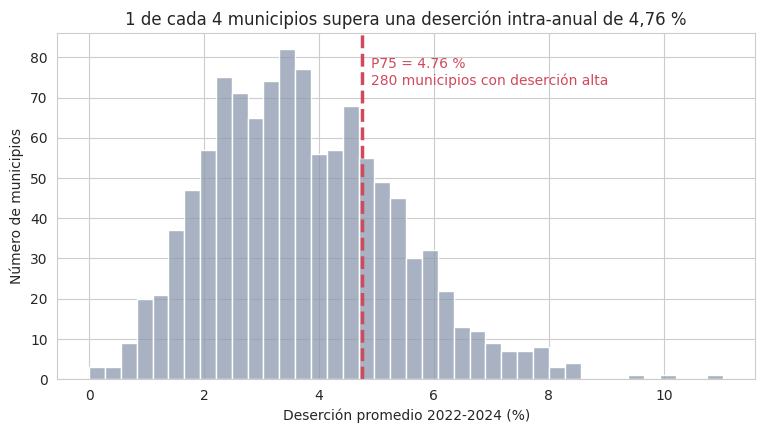

In [22]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(base['desercion_prom'], bins=40, color=GRIS, ax=ax)
ax.axvline(p75, color=ROJO, ls='--', lw=2.5)
ax.text(p75 + 0.15, ax.get_ylim()[1] * 0.85, f"P75 = {p75:.2f} %\n{base['desercion_alta'].sum()} municipios con deserción alta", color=ROJO)
ax.set(title='1 de cada 4 municipios supera una deserción intra-anual de 4,76 %',
       xlabel='Deserción promedio 2022-2024 (%)', ylabel='Número de municipios')
plt.savefig('outputs/figures/fig01_distribucion_target.png', dpi=160, bbox_inches='tight')
plt.show()

### Hipótesis de la segunda entrega, recalculadas

In [23]:
h1 = base.groupby('grupo_coca').agg(municipios=('cod_mpio', 'count'), desercion_media=('desercion_prom', 'mean'),
                                    pct_desercion_alta=('desercion_alta', 'mean'))
h1['pct_desercion_alta'] = 100 * h1['pct_desercion_alta']

robustez = (base.groupby('grupo_coca')[['desercion_alta', 'desercion_alta_p80', 'desercion_alta_p90']].mean() * 100).T
robustez.index = ['P75', 'P80', 'P90']
robustez['razón'] = robustez['Con coca'] / robustez['Sin coca']

promedio_depto = base.groupby('departamento')['desercion_prom'].transform('mean')
media_nacional = base['desercion_prom'].mean()
pct_depto = 100 * ((promedio_depto - media_nacional) ** 2).sum() / ((base['desercion_prom'] - media_nacional) ** 2).sum()
base['dif_vs_depto'] = base['desercion_prom'] - promedio_depto

pdet_sin_coca = 100 * base.loc[(base['pdet'] == 1) & (base['coca_presencia'] == 0), 'desercion_alta'].mean()
narino = base[base['departamento'] == 'Nariño']['desercion_prom'].mean()
depto_min = base.groupby('departamento')['desercion_prom'].mean()

comparacion = pd.DataFrame({
    'Indicador': ['Municipios en la base', 'Umbral P75 (%)', 'Municipios con coca', '% deserción alta con coca',
                  '% deserción alta sin coca', 'Razón P75', 'Razón P80', 'Razón P90',
                  '% de la variación explicado por el departamento', 'Diferencia vs. su departamento, con coca (p.p.)',
                  '% deserción alta PDET sin coca', 'Deserción promedio de Nariño (%)', 'Rho IPM vs. deserción'],
    'Segunda entrega': [1122, 4.77, 189, 40.74, 21.86, 1.86, 1.96, 2.60, 44.5, 0.44, 47.0, 2.2, 0.00],
    'Ahora': [len(base), p75, base['coca_presencia'].sum(), h1.loc['Con coca', 'pct_desercion_alta'], h1.loc['Sin coca', 'pct_desercion_alta'],
              robustez.loc['P75', 'razón'], robustez.loc['P80', 'razón'], robustez.loc['P90', 'razón'], pct_depto,
              base.loc[base['coca_presencia'] == 1, 'dif_vs_depto'].mean(), pdet_sin_coca, narino, ev.loc['ipm', 'rho_desercion']]})
comparacion

,Indicador,Segunda entrega,Ahora
0,Municipios en la base,"1,122.00","1,121.00"
1,Umbral P75 (%),4.77,4.76
2,Municipios con coca,189.00,189.00
3,% deserción alta con coca,40.74,40.74
4,% deserción alta sin coca,21.86,21.78
5,Razón P75,1.86,1.87
6,Razón P80,1.96,1.97
7,Razón P90,2.60,2.63
8,% de la variación explicado por el departamento,44.50,44.86
9,"Diferencia vs. su departamento, con coca (p.p.)",0.44,0.45


### Hallazgo 1: el IPM agregado esconde privaciones que van en direcciones opuestas

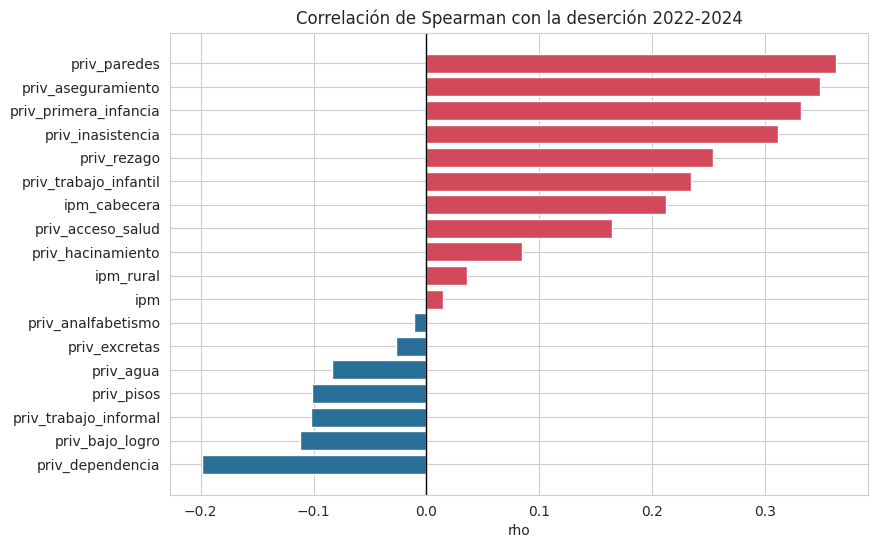

In [24]:
rho_priv = ev.loc[privaciones + ['ipm', 'ipm_cabecera', 'ipm_rural'], 'rho_desercion'].sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(rho_priv.index, rho_priv.values, color=[ROJO if v > 0 else AZUL for v in rho_priv.values])
ax.axvline(0, color='black', lw=1)
ax.set(title='Correlación de Spearman con la deserción 2022-2024', xlabel='rho')
plt.savefig('outputs/figures/fig11_privaciones_ipm.png', dpi=160, bbox_inches='tight')
plt.show()

### Hallazgo 2: la deserción es persistente

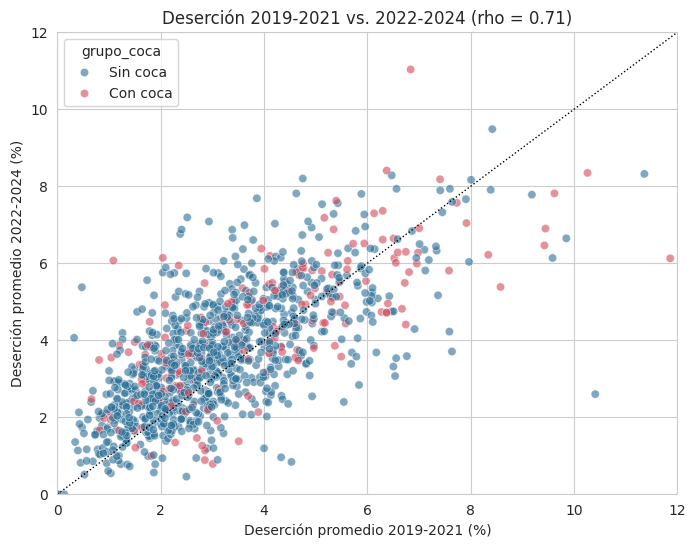

In [25]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=base, x='desercion_lag', y='desercion_prom', hue='grupo_coca', palette=COLORES, alpha=0.6, ax=ax)
ax.plot([0, 12], [0, 12], color='black', ls=':', lw=1)
ax.set(xlim=(0, 12), ylim=(0, 12), title=f"Deserción 2019-2021 vs. 2022-2024 (rho = {ev.loc['desercion_lag', 'rho_desercion']:.2f})",
       xlabel='Deserción promedio 2019-2021 (%)', ylabel='Deserción promedio 2022-2024 (%)')
plt.savefig('outputs/figures/fig12_persistencia_desercion.png', dpi=160, bbox_inches='tight')
plt.show()

In [26]:
transicion = pd.crosstab(np.where(base['desercion_lag'] > base['desercion_lag'].quantile(0.75), 'Alta 2019-2021', 'No alta 2019-2021'),
                         base['desercion_alta'].map({1: 'Alta 2022-2024', 0: 'No alta 2022-2024'}), normalize='index') * 100
transicion

desercion_alta,Alta 2022-2024,No alta 2022-2024
row_0,,
Alta 2019-2021,63.93,36.07
No alta 2019-2021,12.01,87.99


### Hallazgo 3: salir de la coca no reduce la deserción (al menos no pronto)

In [27]:
orden_din = ['Sin coca', 'Salió', 'Entró', 'Persistente']
dinamica = base.groupby('dinamica_coca').agg(municipios=('cod_mpio', 'count'), desercion_media=('desercion_prom', 'mean'),
                                             pct_desercion_alta=('desercion_alta', 'mean'),
                                             desercion_2019_2021=('desercion_lag', 'mean')).loc[orden_din]
dinamica['pct_desercion_alta'] = 100 * dinamica['pct_desercion_alta']
dinamica

,municipios,desercion_media,pct_desercion_alta,desercion_2019_2021
dinamica_coca,,,,
Sin coca,888,3.53,20.61,3.06
Salió,44,4.59,45.45,3.91
Entró,7,4.74,57.14,3.40
Persistente,182,4.43,40.11,4.10


In [28]:
con_coca_historica = base['anios_coca_largo'] > 0
print("Correlaciones de Spearman con la deserción, solo municipios con coca alguna vez (2001-2023):",
      con_coca_historica.sum(), "municipios")
base.loc[con_coca_historica, ['anios_coca', 'anios_coca_largo', 'log_ha_coca', 'cambio_coca', 'desercion_prom']].corr(method='spearman')['desercion_prom'].drop('desercion_prom')

Correlaciones de Spearman con la deserción, solo municipios con coca alguna vez (2001-2023): 318 municipios


anios_coca          0.24
anios_coca_largo    0.35
log_ha_coca         0.20
cambio_coca        -0.09
Name: desercion_prom, dtype: float64

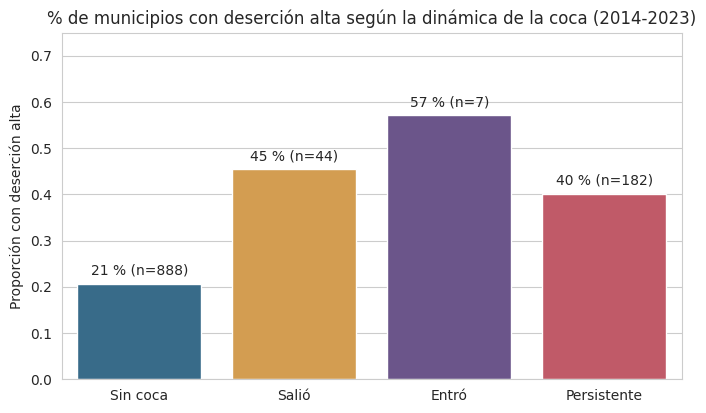

In [29]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=base, x='dinamica_coca', y='desercion_alta', order=orden_din,
            palette=[AZUL, '#e9a03b', '#6a4c93', ROJO], errorbar=None, ax=ax)
ax.set(title='% de municipios con deserción alta según la dinámica de la coca (2014-2023)', xlabel='', ylabel='Proporción con deserción alta', ylim=(0, 0.75))
for i, (n, v) in enumerate(zip(dinamica['municipios'], dinamica['pct_desercion_alta'])):
    ax.text(i, v / 100 + 0.02, f"{v:.0f} % (n={n})", ha='center')
plt.savefig('outputs/figures/fig13_dinamica_coca.png', dpi=160, bbox_inches='tight')
plt.show()

### Hallazgo 4: el caso de Nariño se explica por su sistema escolar

In [30]:
deptos_coca = (base.groupby('departamento')
               .agg(municipios=('cod_mpio', 'count'), pct_coca=('coca_presencia', 'mean'), desercion=('desercion_prom', 'mean'),
                    desercion_2019_2021=('desercion_lag', 'mean'), reprobacion_2019_2021=('reprobacion_lag', 'mean'),
                    cob_media_2019_2021=('cob_neta_media_lag', 'mean'), inasistencia_2018=('priv_inasistencia', 'mean'),
                    victimas=('log_victimas_x1000', 'mean')))
deptos_coca = deptos_coca[(deptos_coca['pct_coca'] >= 0.3) & (deptos_coca['municipios'] >= 5)].sort_values('desercion')
deptos_coca

,municipios,pct_coca,desercion,desercion_2019_2021,reprobacion_2019_2021,cob_media_2019_2021,inasistencia_2018,victimas
departamento,,,,,,,,
Nariño,64,0.42,2.17,1.73,4.40,42.68,4.76,2.10
Chocó,30,0.67,3.30,3.32,8.90,24.09,8.14,3.85
Cauca,42,0.62,3.56,2.58,7.29,33.96,5.19,2.74
Norte de Santander,40,0.38,3.82,3.76,6.69,35.70,7.30,1.96
Bolívar,46,0.33,3.82,2.58,4.90,38.61,6.08,2.13
Putumayo,13,0.69,5.97,7.22,6.19,41.38,4.42,2.32
Caquetá,16,0.94,6.51,6.41,6.52,29.78,8.09,2.96


### Hallazgo 5: ¿la cobertura o la reprobación absorben la relación con la coca?

In [31]:
def terciles(columna):
    return pd.qcut(base[columna], q=3, labels=['Bajo', 'Medio', 'Alto'])

for col, nombre in [('cob_neta_media_lag', 'Cobertura neta en media 2019-2021'), ('reprobacion_lag', 'Reprobación 2019-2021'),
                    ('desercion_lag', 'Deserción 2019-2021')]:
    tabla = pd.pivot_table(base.assign(tercil=terciles(col)), index='tercil', columns='grupo_coca', values='desercion_prom', aggfunc='mean', observed=True)
    tabla['brecha (p.p.)'] = tabla['Con coca'] - tabla['Sin coca']
    print(f"\n{nombre}")
    display(tabla)


Cobertura neta en media 2019-2021


grupo_coca,Con coca,Sin coca,brecha (p.p.)
tercil,,,
Bajo,4.65,4.06,0.58
Medio,4.22,3.77,0.45
Alto,3.56,3.07,0.49



Reprobación 2019-2021


grupo_coca,Con coca,Sin coca,brecha (p.p.)
tercil,,,
Bajo,4.15,3.09,1.06
Medio,4.40,3.64,0.76
Alto,4.66,4.07,0.60



Deserción 2019-2021


grupo_coca,Con coca,Sin coca,brecha (p.p.)
tercil,,,
Bajo,3.03,2.49,0.54
Medio,3.49,3.61,-0.12
Alto,5.53,4.87,0.65


### Correlaciones entre las variables seleccionadas

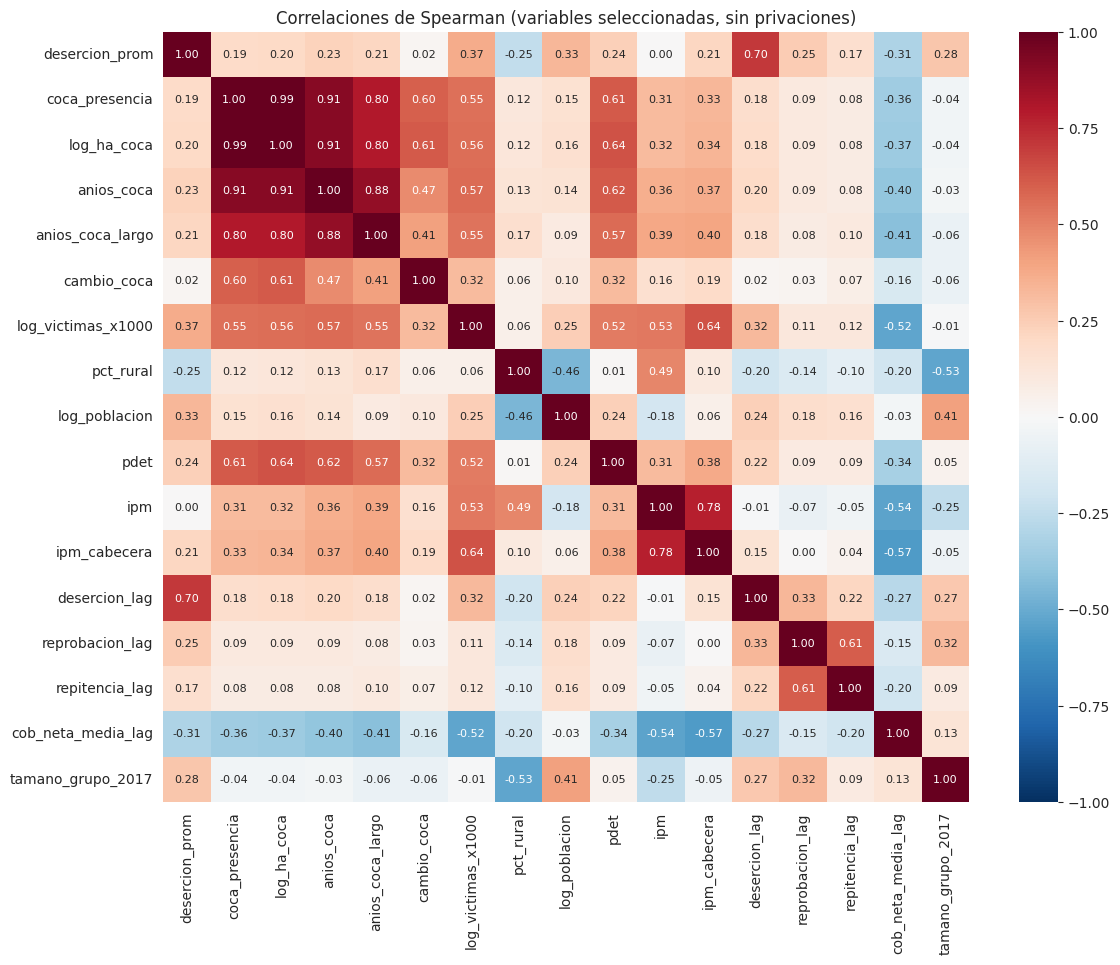

In [32]:
variables_corr = ['desercion_prom', 'coca_presencia', 'log_ha_coca', 'anios_coca', 'anios_coca_largo', 'cambio_coca', 'log_victimas_x1000',
                  'pct_rural', 'log_poblacion', 'pdet', 'ipm', 'ipm_cabecera', 'desercion_lag', 'reprobacion_lag', 'repitencia_lag',
                  'cob_neta_media_lag', 'tamano_grupo_2017']
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(base[variables_corr].corr(method='spearman'), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax, annot_kws={'size': 8})
ax.set_title('Correlaciones de Spearman (variables seleccionadas, sin privaciones)')
plt.savefig('outputs/figures/fig07_correlaciones.png', dpi=160, bbox_inches='tight')
plt.show()

## Reducción de dimensionalidad: PCA sobre las 15 privaciones

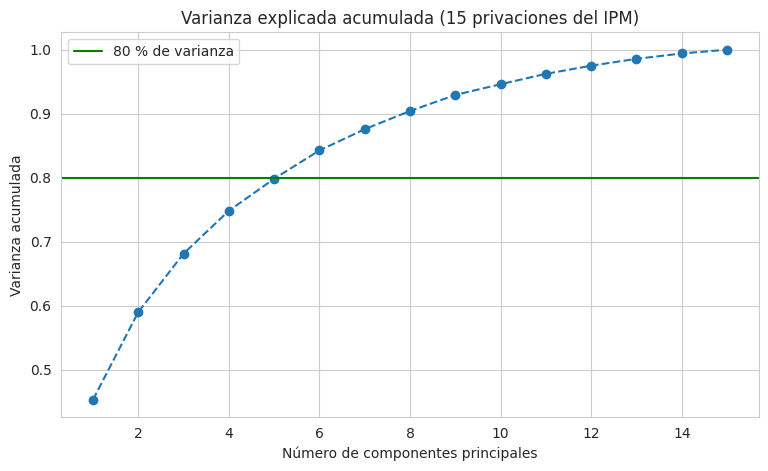

Varianza acumulada de los 4 primeros componentes: [0.45 0.59 0.68 0.75]


In [33]:
scaler_priv = StandardScaler()
priv_scaled = scaler_priv.fit_transform(base[privaciones])
pca_priv = PCA()
pca_priv.fit(priv_scaled)

varianza_acumulada = np.cumsum(pca_priv.explained_variance_ratio_)
plt.figure(figsize=(9, 5))
plt.plot(range(1, len(varianza_acumulada) + 1), varianza_acumulada, marker='o', linestyle='--')
plt.axhline(y=0.8, color='g', linestyle='-', label='80 % de varianza')
plt.title('Varianza explicada acumulada (15 privaciones del IPM)')
plt.xlabel('Número de componentes principales')
plt.ylabel('Varianza acumulada')
plt.legend()
plt.show()
print("Varianza acumulada de los 4 primeros componentes:", varianza_acumulada[:4].round(2))

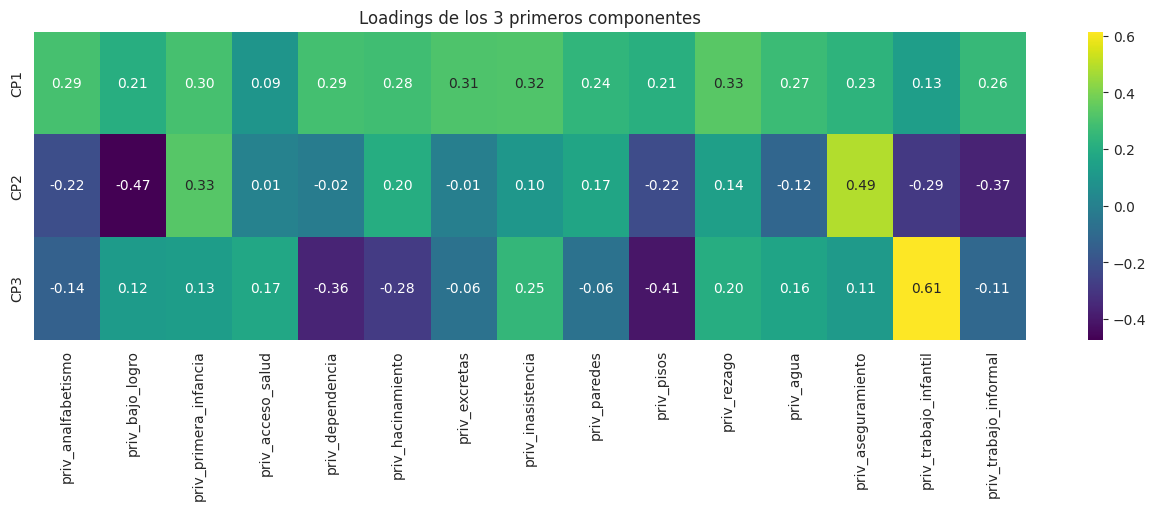

,cp1_pobreza,cp2_pobreza,cp3_pobreza,ipm,desercion_prom
cp1_pobreza,1.00,-0.30,-0.07,0.97,0.07
cp2_pobreza,-0.30,1.00,-0.01,-0.39,0.23
cp3_pobreza,-0.07,-0.01,1.00,-0.10,0.27
ipm,0.97,-0.39,-0.10,1.00,0.00
desercion_prom,0.07,0.23,0.27,0.00,1.00


In [34]:
cargas = pd.DataFrame(pca_priv.components_[:3], columns=privaciones, index=['CP1', 'CP2', 'CP3'])
plt.figure(figsize=(16, 4))
sns.heatmap(cargas, annot=True, cmap='viridis', fmt='.2f')
plt.title('Loadings de los 3 primeros componentes')
plt.show()

componentes = pca_priv.transform(priv_scaled)[:, :3]
base['cp1_pobreza'], base['cp2_pobreza'], base['cp3_pobreza'] = componentes[:, 0], componentes[:, 1], componentes[:, 2]
base[['cp1_pobreza', 'cp2_pobreza', 'cp3_pobreza', 'ipm', 'desercion_prom']].corr(method='spearman').round(2)

## Segmentación de municipios con K-Means

In [35]:
variables_cluster = ['log_ha_coca', 'anios_coca', 'log_victimas_x1000', 'cp1_pobreza', 'cp2_pobreza', 'pct_rural']
variables_cluster_2a = ['log_ha_coca', 'anios_coca', 'log_victimas_x1000', 'ipm', 'pct_rural']

X_cluster = StandardScaler().fit_transform(base[variables_cluster])
X_cluster_2a = StandardScaler().fit_transform(base[variables_cluster_2a])

resultados_k = []
for k in range(2, 11):
    etiquetas = KMeans(n_clusters=k, init='k-means++', max_iter=300, n_init=10, random_state=SEMILLA).fit(X_cluster)
    etiquetas_2a = KMeans(n_clusters=k, init='k-means++', max_iter=300, n_init=10, random_state=SEMILLA).fit_predict(X_cluster_2a)
    resultados_k.append({'k': k, 'WCSS': etiquetas.inertia_, 'silueta': silhouette_score(X_cluster, etiquetas.labels_),
                         'silueta_especificación_2a_entrega': silhouette_score(X_cluster_2a, etiquetas_2a)})
resultados_k = pd.DataFrame(resultados_k)
resultados_k

,k,WCSS,silueta,silueta_especificación_2a_entrega
0,2,"4,121.52",0.51,0.55
1,3,"3,020.64",0.34,0.34
2,4,"2,435.33",0.36,0.33
3,5,"2,115.87",0.33,0.34
4,6,"1,913.56",0.28,0.32
5,7,"1,732.28",0.27,0.29
6,8,"1,585.48",0.27,0.29
7,9,"1,492.74",0.27,0.28
8,10,"1,411.75",0.27,0.29


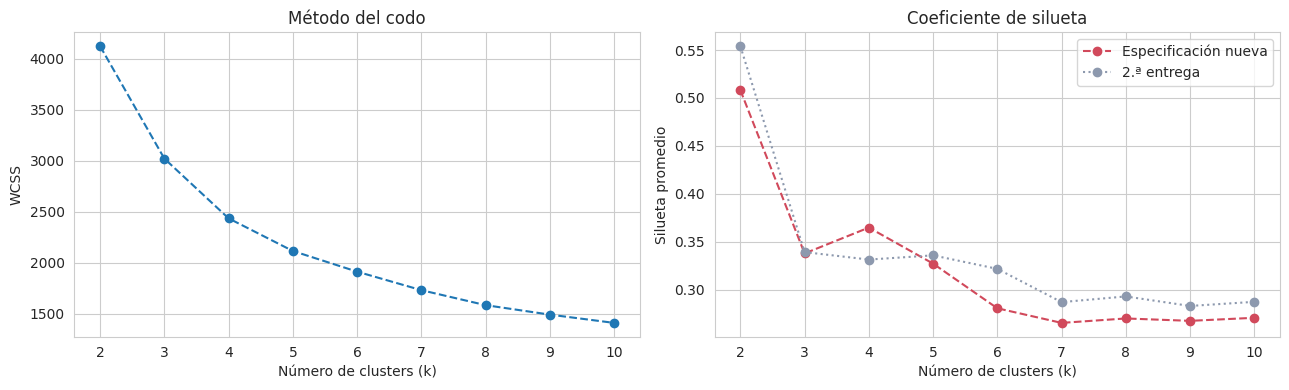

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(resultados_k['k'], resultados_k['WCSS'], marker='o', linestyle='--')
axes[0].set(title='Método del codo', xlabel='Número de clusters (k)', ylabel='WCSS')
axes[1].plot(resultados_k['k'], resultados_k['silueta'], marker='o', linestyle='--', color=ROJO, label='Especificación nueva')
axes[1].plot(resultados_k['k'], resultados_k['silueta_especificación_2a_entrega'], marker='o', linestyle=':', color=GRIS, label='2.ª entrega')
axes[1].set(title='Coeficiente de silueta', xlabel='Número de clusters (k)', ylabel='Silueta promedio')
axes[1].legend()
plt.tight_layout()
plt.show()

In [37]:
K = 4
kmeans = KMeans(n_clusters=K, init='k-means++', max_iter=300, n_init=10, random_state=SEMILLA)
base['cluster'] = kmeans.fit_predict(X_cluster)
print(f"Silueta con k = {K}: {silhouette_score(X_cluster, base['cluster']):.3f}")

perfil = base.groupby('cluster').agg(municipios=('cod_mpio', 'count'), pct_coca=('coca_presencia', 'mean'),
                                     anios_coca=('anios_coca', 'mean'), victimas_x1000=('victimas_x1000', 'median'),
                                     ipm=('ipm', 'mean'), cp1_pobreza=('cp1_pobreza', 'mean'), cp2_pobreza=('cp2_pobreza', 'mean'),
                                     pct_rural=('pct_rural', 'mean'), cob_media_2019_2021=('cob_neta_media_lag', 'mean'),
                                     desercion_prom=('desercion_prom', 'mean'), pct_desercion_alta=('desercion_alta', 'mean'))
perfil

Silueta con k = 4: 0.365


,municipios,pct_coca,anios_coca,victimas_x1000,ipm,cp1_pobreza,cp2_pobreza,pct_rural,cob_media_2019_2021,desercion_prom,pct_desercion_alta
cluster,,,,,,,,,,,
0,343,0.01,0.17,0.74,28.06,-1.59,1.28,29.57,47.05,4.09,0.29
1,577,0.02,0.23,0.95,43.78,-0.08,-0.85,66.79,45.99,3.30,0.17
2,163,1.00,9.57,26.71,53.37,1.65,-0.37,60.97,31.84,4.50,0.41
3,38,0.21,2.42,4.79,84.40,8.54,2.93,88.37,8.79,3.65,0.39


### Nombrar los clusters

In [38]:
cocalero = perfil['anios_coca'].idxmax()
resto = perfil.drop(cocalero)
dispersa = resto['cp1_pobreza'].idxmax()
resto = resto.drop(dispersa)
urbano = resto['pct_rural'].idxmin()
rural = resto.drop(urbano).index[0]

nombres = {cocalero: 'Cocalero con conflicto', dispersa: 'Rural disperso de pobreza extrema',
           urbano: 'Urbano e intermedio', rural: 'Rural sin coca'}
base['tipologia'] = base['cluster'].map(nombres)
perfil.index = perfil.index.map(nombres)
perfil['pct_desercion_alta'] = 100 * perfil['pct_desercion_alta']
perfil['pct_coca'] = 100 * perfil['pct_coca']
perfil.sort_values('pct_desercion_alta', ascending=False)

,municipios,pct_coca,anios_coca,victimas_x1000,ipm,cp1_pobreza,cp2_pobreza,pct_rural,cob_media_2019_2021,desercion_prom,pct_desercion_alta
cluster,,,,,,,,,,,
Cocalero con conflicto,163,100.00,9.57,26.71,53.37,1.65,-0.37,60.97,31.84,4.50,41.10
Rural disperso de pobreza extrema,38,21.05,2.42,4.79,84.40,8.54,2.93,88.37,8.79,3.65,39.47
Urbano e intermedio,343,1.17,0.17,0.74,28.06,-1.59,1.28,29.57,47.05,4.09,29.15
Rural sin coca,577,2.43,0.23,0.95,43.78,-0.08,-0.85,66.79,45.99,3.30,16.98


In [39]:
print("Departamentos del cluster 'Rural disperso de pobreza extrema':")
print(base[base['tipologia'] == 'Rural disperso de pobreza extrema']['departamento'].value_counts().head(8))

Departamentos del cluster 'Rural disperso de pobreza extrema':
departamento
Amazonas      10
Guainía        7
Chocó          6
Vaupés         6
La Guajira     3
Antioquia      2
Boyacá         1
Cesar          1
Name: count, dtype: int64


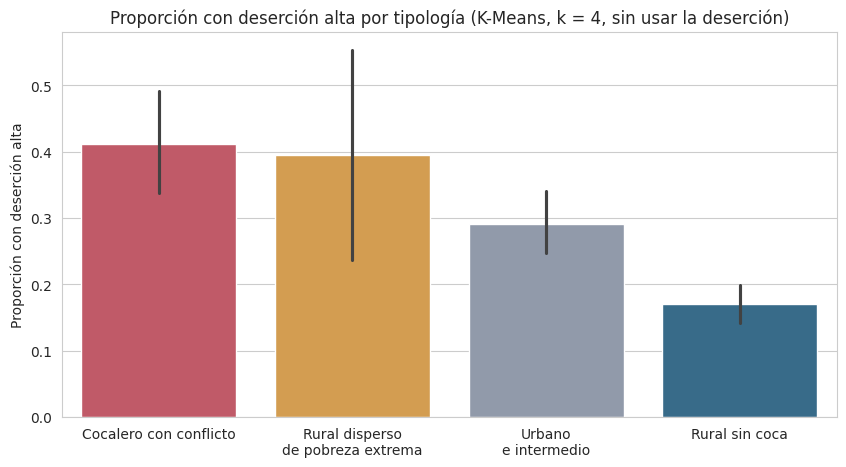

In [40]:
fig, ax = plt.subplots(figsize=(10, 5))
orden = perfil.sort_values('pct_desercion_alta', ascending=False).index
paleta = {'Cocalero con conflicto': ROJO, 'Rural disperso de pobreza extrema': '#e9a03b', 'Urbano e intermedio': GRIS, 'Rural sin coca': AZUL}
sns.barplot(data=base, x='tipologia', y='desercion_alta', order=orden, palette=paleta, ax=ax)
ax.set_xticklabels([t.replace(' de ', '\nde ').replace(' e ', '\ne ') for t in orden])
ax.set(title=f'Proporción con deserción alta por tipología (K-Means, k = {K}, sin usar la deserción)', xlabel='', ylabel='Proporción con deserción alta')
plt.savefig('outputs/figures/fig10_kmeans_tipologias.png', dpi=160, bbox_inches='tight')
plt.show()

## Guardar resultados

In [41]:
columnas_finales = (['cod_mpio', 'conjunto', 'municipio', 'cod_depto', 'departamento', 'etc', 'subregion_pdet',
                     'desercion_prom', 'desercion_alta', 'desercion_alta_p80', 'desercion_alta_p90',
                     'des_primaria', 'des_secundaria', 'des_media', 'grupo_coca', 'dinamica_coca', 'tipologia',
                     'ha_coca_prom', 'victimas_prom', 'victimas_x1000', 'pob_total', 'pob_5_16']
                    + [v for v in candidatas if not v.endswith('_2224')] + ['cp1_pobreza', 'cp2_pobreza', 'cp3_pobreza'])
columnas_finales = list(dict.fromkeys(columnas_finales))
base[columnas_finales].to_csv('data/processed/base_municipal.csv', index=False, encoding='utf-8-sig')

inventario.to_csv('outputs/reports/inventario_variables.csv', index=False, encoding='utf-8-sig')
comparacion.to_csv('outputs/reports/comparacion_segunda_entrega_eda.csv', index=False, encoding='utf-8-sig')
perfil.to_csv('outputs/reports/perfil_tipologias_kmeans.csv', encoding='utf-8-sig')
print("Base municipal:", base[columnas_finales].shape)

Base municipal: (1121, 88)
